In [1]:
# !pip install opencv-python pytesseract pillow matplotlib pandas numpy

In [2]:
import cv2
import numpy as np
import pytesseract
import matplotlib.pyplot as plt
import pandas as pd
import re
import difflib

# Jika Tesseract tidak ada di PATH (khususnya Windows), set manual, contoh:
# pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

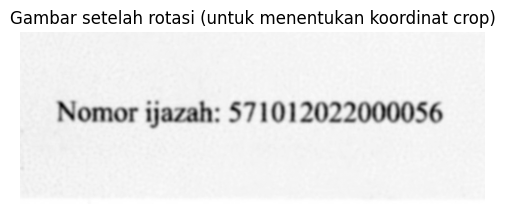

In [22]:
IMAGE_PATH = "03_Blurred(1).jpg"  # ganti sesuai lokasi file Anda

img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Gambar tidak ditemukan: {IMAGE_PATH}")

# Putar gambar agar teks tegak (sesuaikan arah rotasi jika perlu)
#img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

gray_full = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(6, 8))
plt.imshow(gray_full, cmap="gray")
plt.title("Gambar setelah rotasi (untuk menentukan koordinat crop)")
plt.axis("off")
plt.show()

In [24]:
GROUND_TRUTH = "571012022000056"  # sesuaikan dengan nomor ijazah yang sebenarnya
print("Ground truth:", GROUND_TRUTH, "| panjang:", len(GROUND_TRUTH))

Ground truth: 571012022000056 | panjang: 15


In [25]:
def apply_mean(image, ksize=5):
    """Mean (average) filter - meredam noise dengan merata-ratakan piksel bertetangga."""
    return cv2.blur(image, (ksize, ksize))

def apply_median(image, ksize=5):
    """Median filter - efektif untuk salt-and-pepper noise, mempertahankan tepi lebih baik."""
    return cv2.medianBlur(image, ksize)

def apply_gaussian(image, ksize=5, sigma=0):
    """Gaussian filter - smoothing dengan bobot mengikuti distribusi Gaussian."""
    return cv2.GaussianBlur(image, (ksize, ksize), sigma)

def apply_sharpen(image):
    """Sharpening - mempertajam tepi karakter menggunakan kernel high-pass sederhana."""
    kernel = np.array([[ 0, -1,  0],
                        [-1,  5, -1],
                        [ 0, -1,  0]])
    return cv2.filter2D(image, -1, kernel)

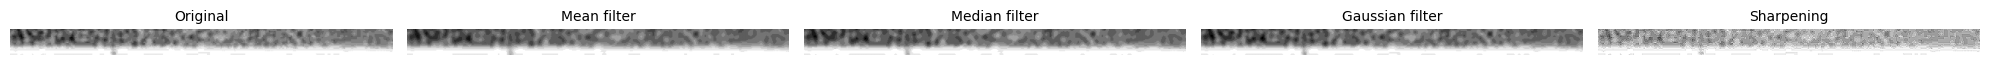

In [31]:
images = {
    "Original":        roi.copy(),
    "Mean filter":     apply_mean(roi),
    "Median filter":   apply_median(roi),
    "Gaussian filter": apply_gaussian(roi),
    "Sharpening":      apply_sharpen(roi),
}

fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4))
for ax, (name, im) in zip(axes, images.items()):
    ax.imshow(im, cmap="gray")
    ax.set_title(name, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [30]:
rows = []
# Ganti 'processed_images' menjadi 'images' (atau sesuaikan dengan nama variabel Anda)
for name, im in images.items(): 
    raw_text = pytesseract.image_to_string(im, config=TESSERACT_CONFIG)
    ocr_clean, correct_chars, accuracy = char_accuracy(raw_text, GROUND_TRUTH)
    
    rows.append({
        "Metode": name,
        "Hasil OCR": ocr_clean if ocr_clean else "(kosong)",
        "Karakter Benar": f"{correct_chars}/{len(GROUND_TRUTH)}",
        "Akurasi (%)": round(accuracy, 2),
    })

df_results = pd.DataFrame(rows)
df_results

,Metode,Hasil OCR,Karakter Benar,Akurasi (%)
0,Original,(kosong),0/15,0.0
1,Mean filter,(kosong),0/15,0.0
2,Median filter,(kosong),0/15,0.0
3,Gaussian filter,(kosong),0/15,0.0
4,Sharpening,(kosong),0/15,0.0


In [20]:
print(df_results.to_string(index=False))

         Metode        Hasil OCR Karakter Benar  Akurasi (%)
       Original  571012022000056          15/15        100.0
    Mean filter  571012022000056          15/15        100.0
  Median filter  571012022000056          15/15        100.0
Gaussian filter 5710120220000564          15/15        100.0
     Sharpening  571012022000056          15/15        100.0
